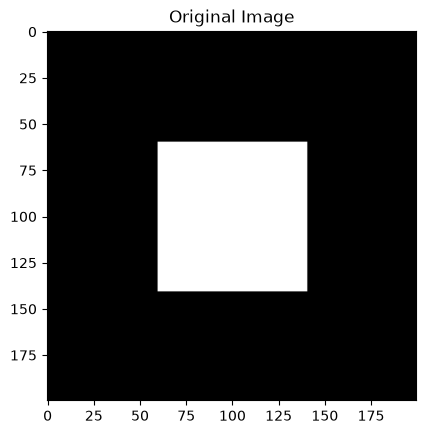

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = np.zeros((200, 200), dtype=np.uint8)
cv2.rectangle(img, (60, 60), (140, 140), 255, -1)

plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.show()

kernel = np.ones((5, 5), np.uint8)

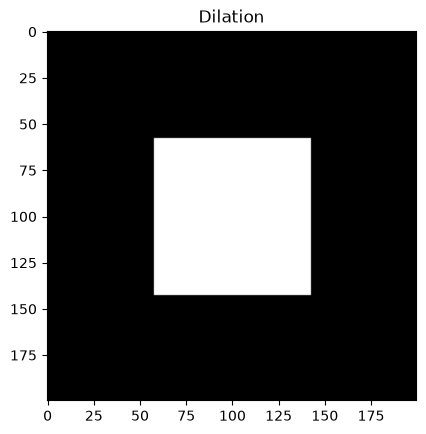

In [3]:
dilated = cv2.dilate(img, kernel, iterations=1)
plt.imshow(dilated, cmap='gray')
plt.title("Dilation")
plt.show()

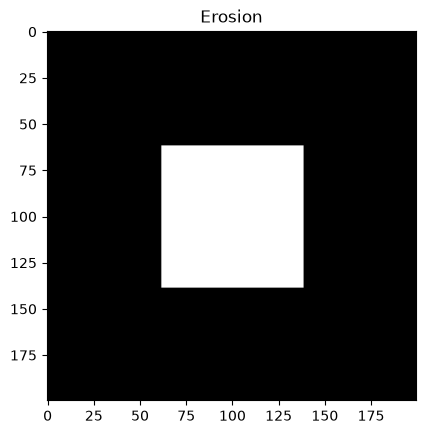

In [4]:
eroded = cv2.erode(img, kernel, iterations=1)
plt.imshow(eroded, cmap='gray')
plt.title("Erosion")
plt.show()

In [5]:
square = np.ones((5, 5), np.uint8)

cross = cv2.getStructuringElement(
    cv2.MORPH_CROSS, (5, 5)
)

ellipse = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (5, 5)
)

print(square)
print(cross)
print(ellipse)

[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


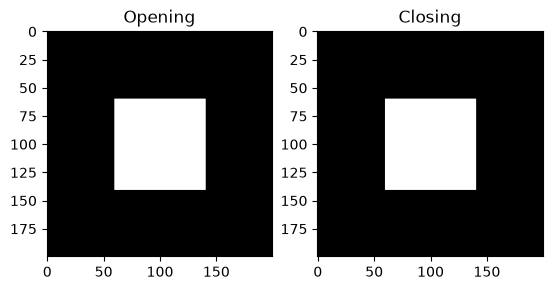

In [6]:
opened = cv2.morphologyEx(
    img, cv2.MORPH_OPEN, kernel
)

closed = cv2.morphologyEx(
    img, cv2.MORPH_CLOSE, kernel
)

plt.subplot(1, 2, 1)
plt.imshow(opened, cmap='gray')
plt.title("Opening")

plt.subplot(1, 2, 2)
plt.imshow(closed, cmap='gray')
plt.title("Closing")

plt.show()

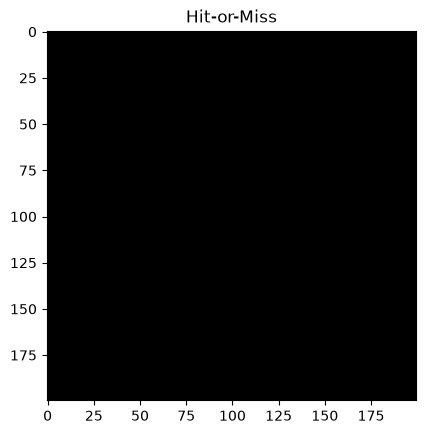

In [7]:
img_binary = (img > 0).astype(np.uint8)

kernel_hit = np.array([
    [0, -1, 0],
    [-1, 1, -1],
    [0, -1, 0]
], dtype=np.int8)

hit_miss = cv2.morphologyEx(
    img_binary, cv2.MORPH_HITMISS, kernel_hit
)

plt.imshow(hit_miss, cmap='gray')
plt.title("Hit-or-Miss")
plt.show()

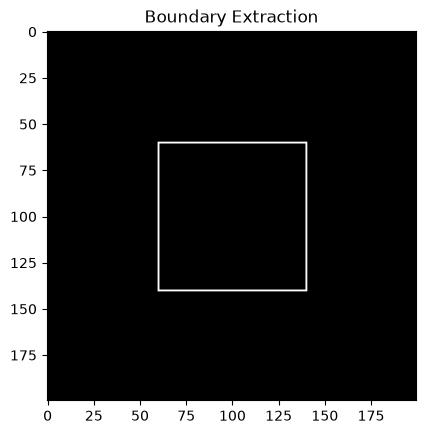

In [8]:
eroded = cv2.erode(
    img, np.ones((3, 3), np.uint8)
)

boundary = cv2.subtract(img, eroded)

plt.imshow(boundary, cmap='gray')
plt.title("Boundary Extraction")
plt.show()

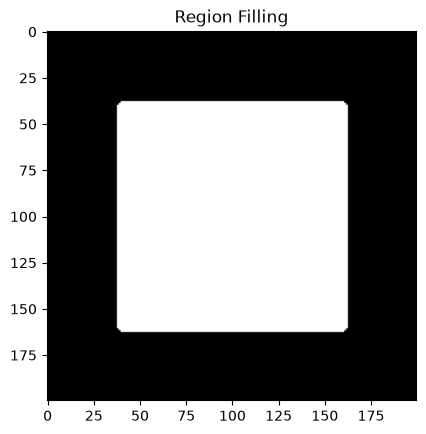

In [9]:
hollow = np.zeros((200, 200), dtype=np.uint8)

cv2.rectangle(hollow, (40, 40), (160, 160), 255, 3)

flood = hollow.copy()
mask = np.zeros((202, 202), dtype=np.uint8)

cv2.floodFill(flood, mask, (0, 0), 255)

holes = cv2.bitwise_not(flood)
filled = cv2.bitwise_or(hollow, holes)

plt.imshow(filled, cmap='gray')
plt.title("Region Filling")
plt.show()